In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 2.3

### a)
![3a](drawings/3a.png)

In [9]:
n : int = 2
x = np.array([0, 1, 2])
f = np.expm1(x)

def neville_schema(x, f, x0):
    n = len(x) - 1
    N = np.zeros((n + 1, n + 1))
    N[:, 0] = f
    for m in range(1, n + 1):
        for j in range(0, n - m + 1):
            N[j, m] = ((x0 - x[j]) * N[j + 1, m - 1] - (x0 - x[j + m]) * N[j, m - 1]) \
                    / (x[j + m] - x[j])
    return N

print(neville_schema(x, f, 1))

[[0.         1.71828183 1.71828183]
 [1.71828183 1.71828183 0.        ]
 [6.3890561  0.         0.        ]]


### b)

![3b](drawings/3b.png)

In [36]:
f = lambda x: np.tan(x)
x0 = np.pi / 4
n_max = 10
h = 2.0 ** -np.arange(n_max + 1)

D = (f(x0 + h) - f(x0 - h)) / (h * 2)

N = neville_schema(h, D, 0)

err = np.abs(N - 2) # f'(Pi / 4) = 2
np.max(err)

np.float64(6.414670761881128)

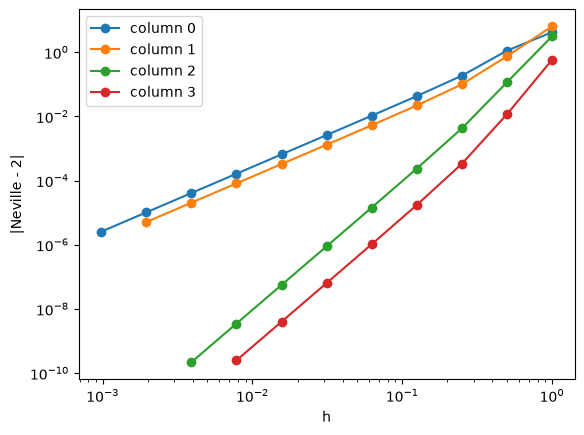

In [37]:
for k in range(4):
    plt.loglog(h[:11-k], err[:11-k, k], 'o-', label=f'column {k}')
plt.legend()
plt.xlabel('h')
plt.ylabel('|Neville - 2|')
plt.show()

Observed convergence rates: columns 0 and 1 converge with rate 2, columns 2 and 3 with rate 4.

0 and 1, 2 and 3 are similar because: D_sym(−h) = D_sym(h) -> its expansion contains only even powers of h:

D_sym(h) = f′(x₀) + c₂h² + c₄h⁴ + ...

To prove we show Taylor expansions for f(x0 + h) and f(x0 - h)